In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/3b01bcb8-0b14-4abf-b6f2-c1bfd384ba69.csv')

df.head()

,country,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg
0,India,Assam,Guwahati,"Railway Colony, Guwahati - PCBA",01-11-2026 23:00:00,26.181742,91.780630,SO2,13.0,25.0,17.0
1,India,Assam,Guwahati,"Railway Colony, Guwahati - PCBA",01-11-2026 23:00:00,26.181742,91.780630,OZONE,12.0,21.0,16.0
2,India,Assam,Nagaon,"Christianpatty, Nagaon - PCBA",01-11-2026 23:00:00,26.349082,92.684490,OZONE,10.0,11.0,10.0
3,India,Assam,Nalbari,"Bata Chowk, Nalbari - PCBA",01-11-2026 23:00:00,26.446912,91.439057,NO2,13.0,16.0,15.0
4,India,Assam,Silchar,"Tarapur, Silchar - PCBA",01-11-2026 23:00:00,24.828270,92.795250,NO2,20.0,22.0,21.0


Clean Column Names

In [ ]:
df.columns = (df.columns
              .str.strip()
              .str.replace("_", " ", regex=False)
              .str.replace("(", "", regex=False)
              .str.replace(")", "", regex=False)
              .str.replace(",", "", regex=False)
              .str.replace("’", "", regex=False)
              .str.replace("'", "", regex=False)
              .str.replace(".", "", regex=False))

Basic Exploratory Data Analysis (EDA)

In [ ]:
# Dataset Overview
print("Dataset Overview:")
print(df)

# Descriptive Statistics
print("\nDescriptive Statistics:")
print(df.describe())

# Dataset Information
print("\nDataset Information:")
df.info()

# First 5 Rows
print("\nFirst 5 Rows:")
print(df.head())

# Last 5 Rows
print("\nLast 5 Rows:")
print(df.tail())

# Column Names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset Shape
print("\nDataset Shape:")
print(df.shape)

# Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Overview:
     country          state           city  \
0      India          Assam       Guwahati   
1      India          Assam       Guwahati   
2      India          Assam         Nagaon   
3      India          Assam        Nalbari   
4      India          Assam        Silchar   
...      ...            ...            ...   
3444   India  Uttar Pradesh  Muzaffarnagar   
3445   India  Uttar Pradesh  Muzaffarnagar   
3446   India  Uttar Pradesh      Moradabad   
3447   India  Uttar Pradesh      Moradabad   
3448   India  Uttar Pradesh          Noida   

                                            station          last update  \
0                   Railway Colony, Guwahati - PCBA  01-11-2026 23:00:00   
1                   Railway Colony, Guwahati - PCBA  01-11-2026 23:00:00   
2                     Christianpatty, Nagaon - PCBA  01-11-2026 23:00:00   
3                        Bata Chowk, Nalbari - PCBA  01-11-2026 23:00:00   
4                           Tarapur, Silchar - PC

Objective 1 — Average Pollutant Levels Across Top 20 Cities

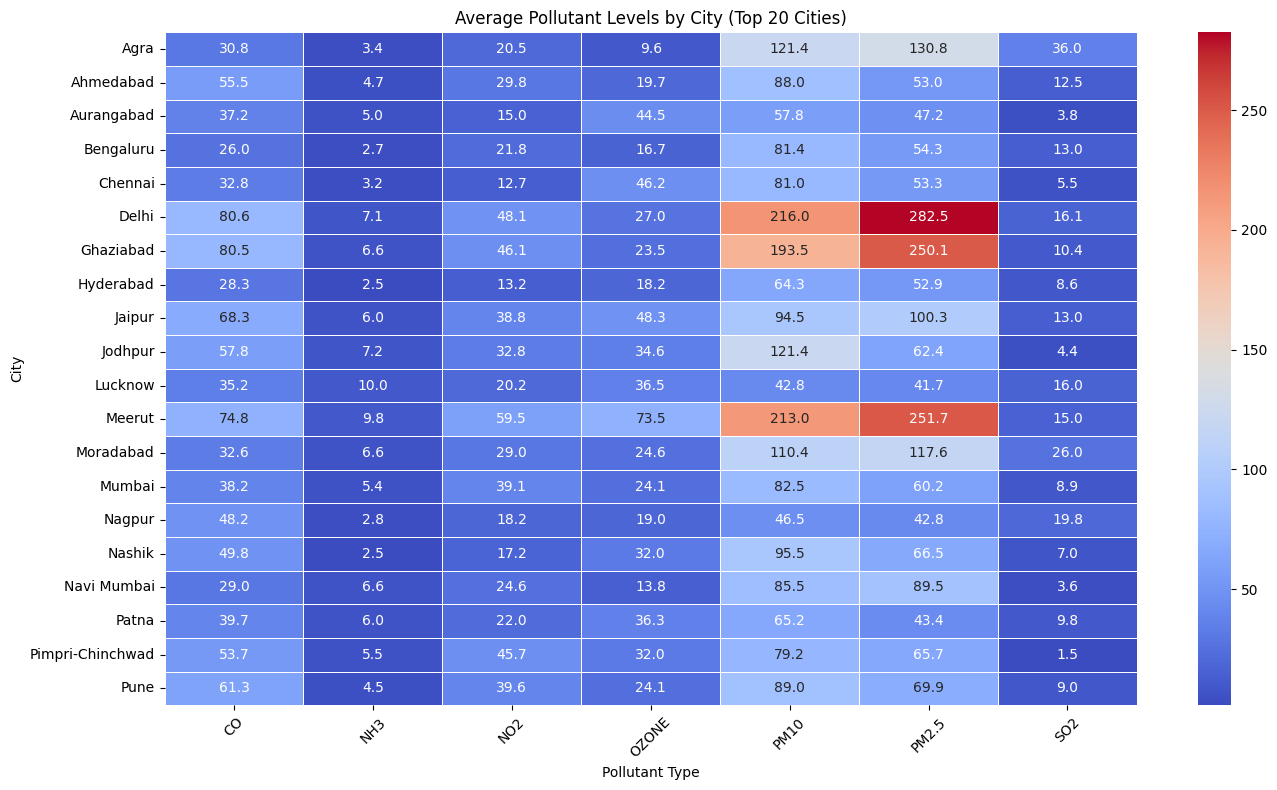

In [ ]:
# Group data by city and pollutant
grouped = df.groupby(['city', 'pollutant id'])['pollutant avg'].mean().reset_index()

# Identify top 20 most monitored cities
top_cities = df['city'].value_counts().head(20).index

# Filter top 20 cities
grouped = grouped[grouped['city'].isin(top_cities)]

# Reshape data for heatmap
reshaped = grouped.pivot(
    index='city',
    columns='pollutant id',
    values='pollutant avg'
)

# Create heatmap
plt.figure(figsize=(14, 8))

sns.heatmap(
    reshaped,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Average Pollutant Levels by City (Top 20 Cities)")
plt.xlabel("Pollutant Type")
plt.ylabel("City")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Objective 2 — Distribution of Average Pollution Levels Across Top 10 Cities

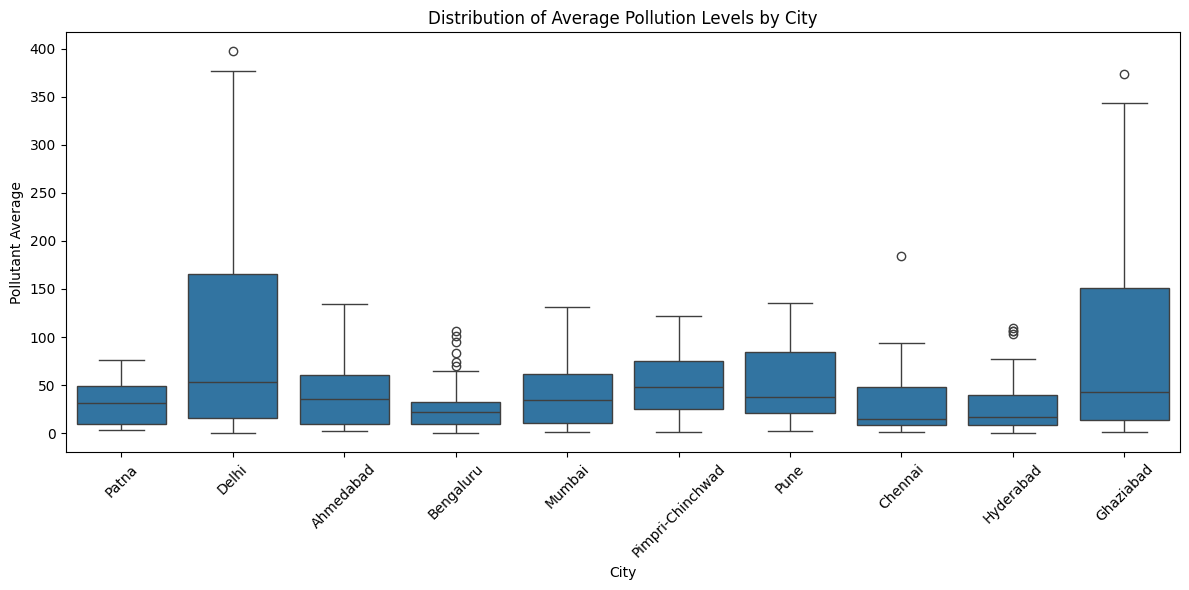

In [ ]:
  # Identify top 10 most monitored cities
top_cities = df['city'].value_counts().head(10).index

# Filter dataset for top 10 cities
filtered_df = df[df['city'].isin(top_cities)]

# Create boxplot
plt.figure(figsize=(12, 6))

sns.boxplot(
    x='city',
    y='pollutant avg',
    data=filtered_df
)

plt.title("Distribution of Average Pollution Levels by City")
plt.xlabel("City")
plt.ylabel("Pollutant Average")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Objective 3 — Geographical Pollution Hotspots in India

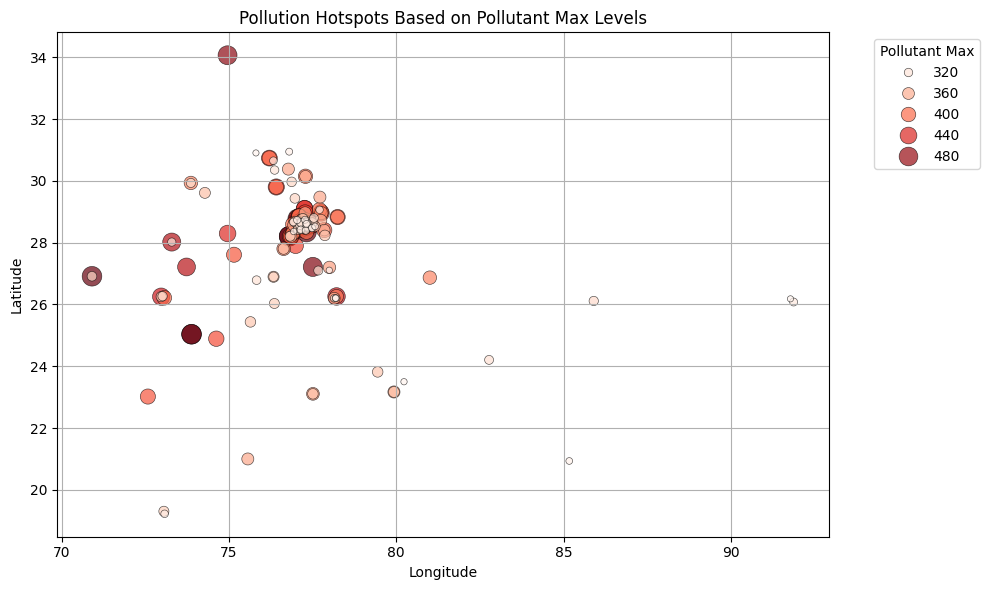

In [ ]:
# Remove rows with missing geographical and pollution values
df_clean = df.dropna(
    subset=['latitude', 'longitude', 'pollutant max']
)

# Select the 200 highest recorded pollution values
df_top = df_clean.sort_values(
    by='pollutant max',
    ascending=False
).head(200)

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_top,
    x='longitude',
    y='latitude',
    hue='pollutant max',
    size='pollutant max',
    palette='Reds',
    sizes=(20, 200),
    alpha=0.7,
    edgecolor='k'
)

plt.title("Pollution Hotspots Based on Pollutant Max Levels")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(
    title='Pollutant Max',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)
plt.grid(True)
plt.tight_layout()
plt.show()

Objective 4 — Most Frequently Monitored Pollutants

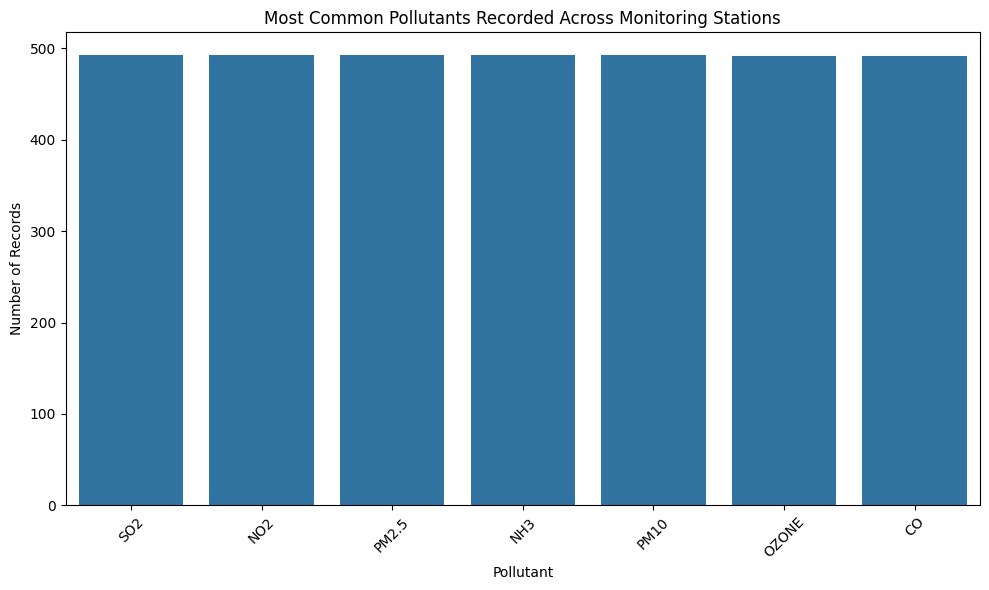

In [ ]:
# Count the frequency of each pollutant
pollutant_counts = df['pollutant id'].value_counts().reset_index()

pollutant_counts.columns = ['pollutant id', 'count']

# Create bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=pollutant_counts,
    x='pollutant id',
    y='count'
)

plt.title("Most Common Pollutants Recorded Across Monitoring Stations")
plt.xlabel("Pollutant")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Objective 5 — PM2.5 Pollution Levels Across Indian States

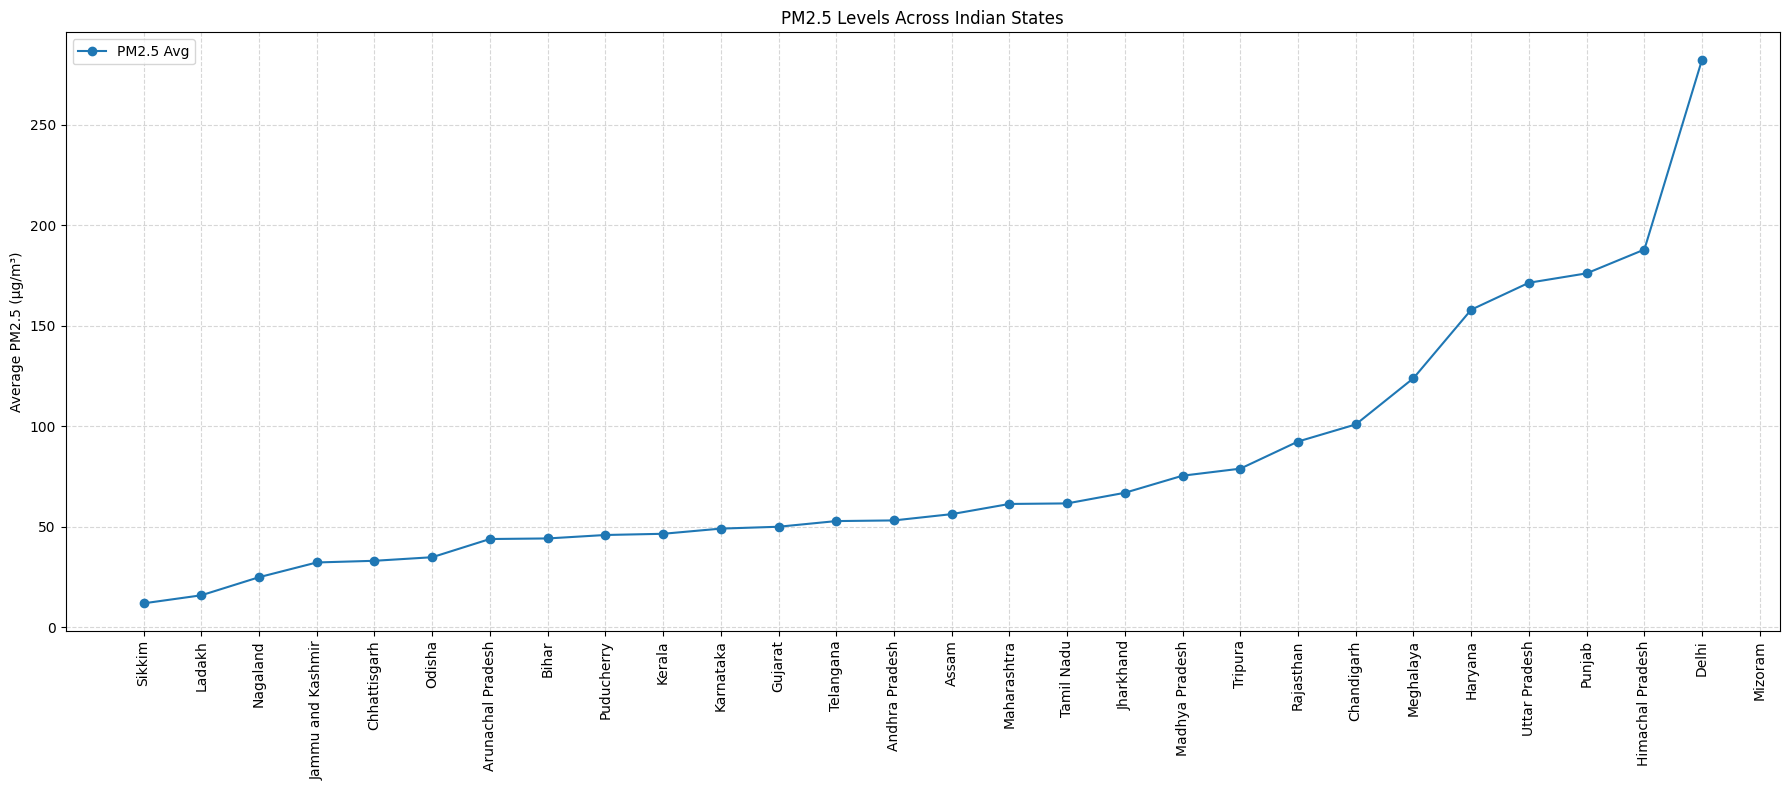

In [ ]:
# Filter data for PM2.5
df_pm25 = df[df['pollutant id'] == 'PM2.5']

# Calculate average PM2.5 levels for each state
state_avg = df_pm25.groupby('state')['pollutant avg'].mean().sort_values()

# Create line plot
plt.figure(figsize=(18, 8))

plt.plot(
    state_avg.index,
    state_avg.values,
    label="PM2.5 Avg",
    marker='o'
)

plt.xticks(rotation=90)
plt.legend()
plt.ylabel("Average PM2.5 (µg/m³)")
plt.title("PM2.5 Levels Across Indian States")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Conclusion

The Air Quality Index Exploratory Data Analysis project examined air pollution patterns across different cities and states in India.

The analysis compared average pollutant levels across the top 20 monitored cities, studied pollution distributions among the top 10 cities, visualized geographical pollution hotspots, identified the most frequently monitored pollutants, and compared state-wise PM2.5 levels.

Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn were used for data cleaning, exploratory data analysis, statistical analysis, and visualization.

The project helped identify patterns and variations in recorded air pollution levels across different locations.